# 01 - Dataset and baseline ERP inference

Frozen model, full ERP in, ERP depth out. This notebook runs the baseline live on one panorama and then loads the dataset-level results written by `python run_experiment.py`.

In [1]:
import os, sys, json
ROOT = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
sys.path.insert(0, ROOT); os.chdir(ROOT)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40)
RES = 'results/midas_dpt_hybrid_synthetic'   # change to e.g. results/dap_stanford2d3d after running DAP
REP = os.path.join(RES, 'report_align-all')
def show(p, w=900):
    p = os.path.join(RES, p) if not os.path.exists(p) else p
    display(Image(filename=p, width=w)) if os.path.exists(p) else print('missing', p)

## Dataset
Procedural indoor panoramas with exact ground-truth range (see `datasets/synthetic.py`). Replace with Stanford2D3D / Matterport3D via the configs in `configs/`.

24 panoramas; (512, 1024, 3) GT range 0.68476826 - 5.066314 m


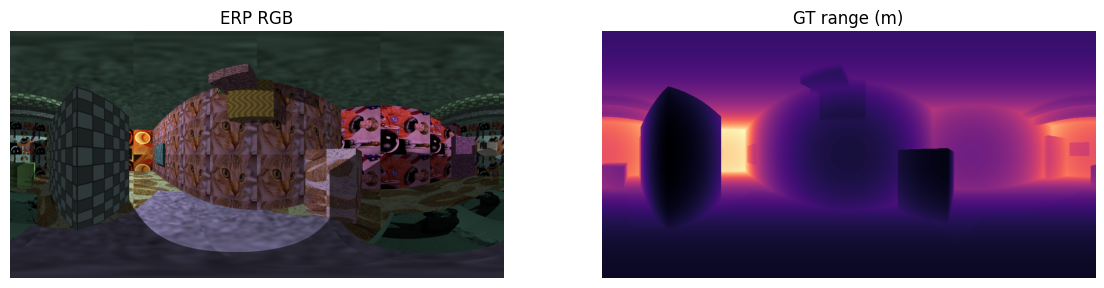

In [2]:
from experiments.common import load_config, make_dataset
cfg = load_config('configs/default.yaml')
ds = make_dataset(cfg)
s = ds[0]
print(len(ds), 'panoramas;', s.rgb.shape, 'GT range', np.nanmin(s.depth), '-', np.nanmax(s.depth), 'm')
fig, ax = plt.subplots(1, 2, figsize=(14, 3.6))
ax[0].imshow(s.rgb); ax[0].set_title('ERP RGB'); ax[1].imshow(s.depth, cmap='magma'); ax[1].set_title('GT range (m)')
[a.axis('off') for a in ax]; plt.show()

## Baseline inference (live, one image)

In [3]:
from models.depth_model import build_model
from evaluation.metrics import to_metric_depth
from evaluation.latitude_analysis import per_band_metrics
model = build_model(dict(cfg['model']))
pred = model.predict(s.rgb, 'erp')
depth, info = to_metric_depth(pred, np.nan_to_num(s.depth, nan=1.0), s.valid, model.spec.space, 'affine')
print(model.describe(), info)
m = per_band_metrics(depth, np.nan_to_num(s.depth, nan=1.0), s.valid)
pd.DataFrame(m).T[['n','abs_rel','sq_rel','rmse','rmse_log','mae','medae','d1','d2','d3','pct_bad']]

/usr/local/lib/python3.11/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'name': 'midas_dpt_hybrid_384', 'space': 'disparity', 'scale': 'affine', 'geometry_erp': 'range', 'geometry_perspective': 'planar', 'device': 'cpu'} {'eval_align': 'affine', 'scale': 0.00024239363296478625, 'shift': 0.49521179768302703}


,n,abs_rel,sq_rel,rmse,rmse_log,mae,medae,d1,d2,d3,pct_bad
all,524288.0,0.199194,0.134472,0.608860,0.278428,0.386141,0.253887,0.675959,0.882257,0.971432,67.453194
0-15,88064.0,0.338449,0.359085,1.073050,0.445068,0.782582,0.506486,0.377600,0.609057,0.893441,88.553779
15-30,86016.0,0.289097,0.257375,0.864353,0.380339,0.645119,0.519104,0.333659,0.734387,0.934966,80.997721
30-45,88064.0,0.191413,0.090389,0.419543,0.245734,0.343305,0.311342,0.590900,0.949548,1.000000,71.899982
45-60,88064.0,0.111749,0.025810,0.192672,0.144058,0.160721,0.151102,0.872513,0.999852,1.000000,47.756177
60-75,86016.0,0.123026,0.028487,0.207654,0.130052,0.178532,0.204243,0.996524,1.000000,1.000000,63.003395
75-90,88064.0,0.141752,0.046081,0.265702,0.156491,0.207778,0.219889,0.884050,1.000000,1.000000,52.719613


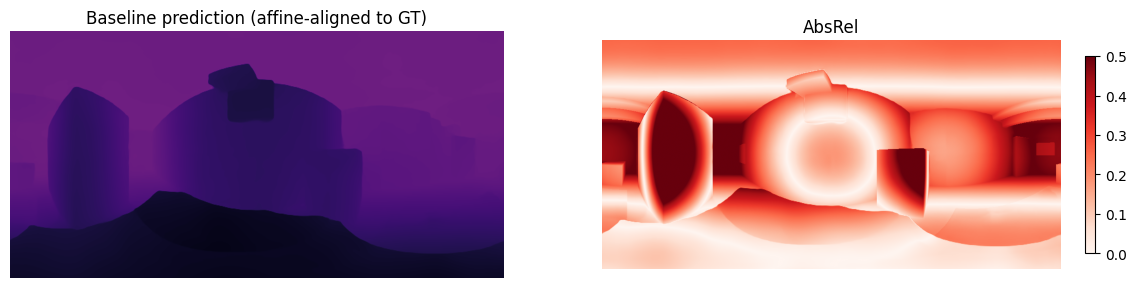

In [4]:
err = np.where(s.valid, np.abs(depth - s.depth) / s.depth, np.nan)
fig, ax = plt.subplots(1, 2, figsize=(14, 3.6))
lo, hi = np.nanpercentile(s.depth, [1, 99])
ax[0].imshow(depth, cmap='magma', vmin=lo, vmax=hi); ax[0].set_title('Baseline prediction (affine-aligned to GT)')
im = ax[1].imshow(err, cmap='Reds', vmin=0, vmax=0.5); ax[1].set_title('AbsRel'); plt.colorbar(im, ax=ax[1], fraction=0.02)
[a.axis('off') for a in ax]; plt.show()

## Dataset-level baseline (from `run_experiment.py`)

In [5]:
pd.read_csv(os.path.join(REP, 'latitude_bands_align-all.csv'), index_col=0)

,abs_rel,rmse,d1,mae,err_var,pct_bad,n
band,,,,,,,
all,0.163040,0.576516,0.743198,0.370909,0.207542,57.953922,524288.0
0-15,0.242677,0.985460,0.531205,0.711420,0.510093,71.311016,88064.0
15-30,0.206820,0.767175,0.601164,0.562679,0.287124,70.077805,86016.0
30-45,0.141514,0.387909,0.801413,0.306790,0.061542,57.189941,88064.0
45-60,0.116200,0.253180,0.873243,0.207925,0.022659,44.270786,88064.0
60-75,0.125896,0.248092,0.858882,0.206529,0.022982,46.971348,86016.0
75-90,0.145286,0.272993,0.792666,0.230747,0.027561,57.929177,88064.0


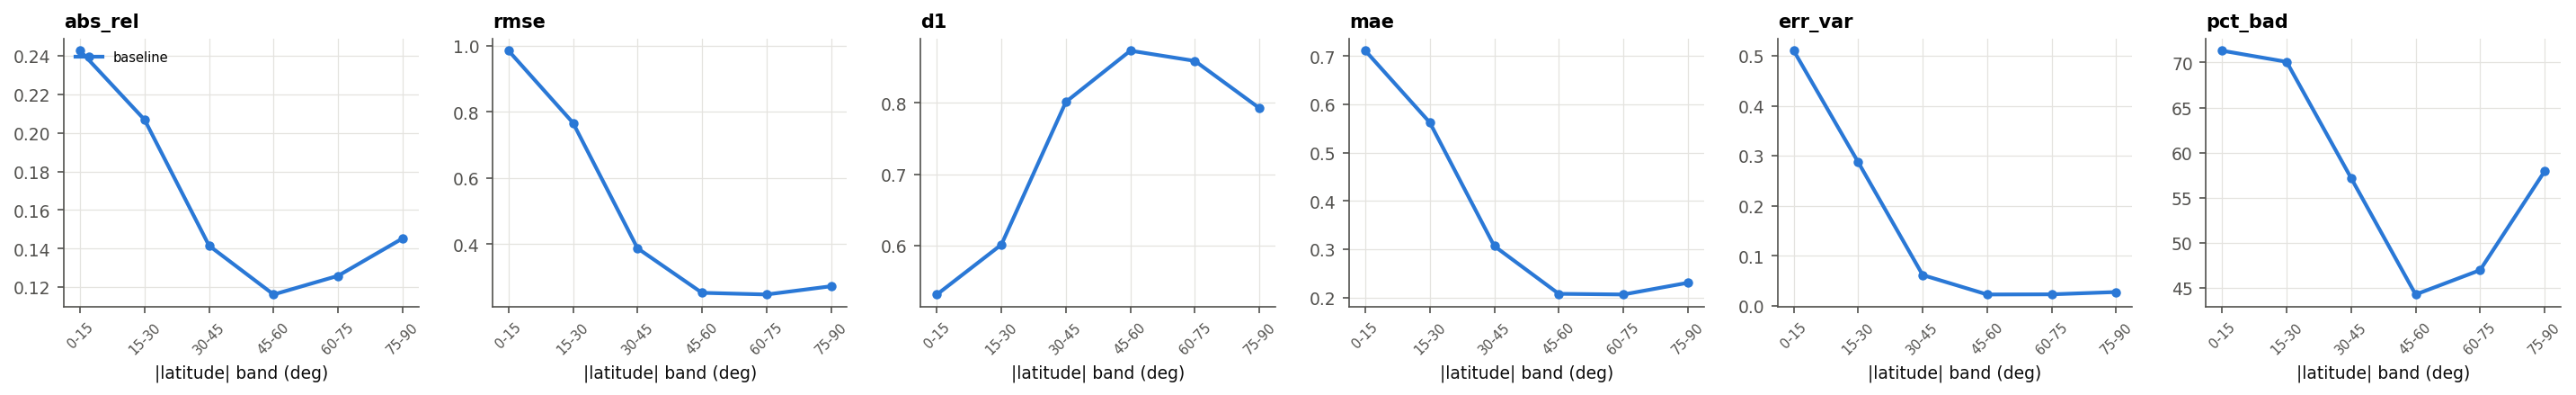

In [6]:
show('report_align-all/baseline_band_metrics_align-all.png')